# Decision model 3: application, action, then parameters
Parameters are extracted by choosing the IDs of the first and last word of a phrase in the transcript.

In [89]:
import json
import time
from typing import cast

from dotenv import load_dotenv
from IPython.display import JSON, display
from typesafe_sdk import Choice, ChoiceAnswer, TypeSafeClient

from demo_helpers import VALID_APPLICATIONS
from demo_helpers import plot_probabilities

load_dotenv()

NONE_OPTION = "none"

In [90]:
transcript = "Hey Google, navigate to Ara."

In [91]:
# Opened once and reused across cells; closed at the end of the notebook
client = TypeSafeClient(model="jev-latest").__enter__()

## Call 1: which application?

In [92]:
app_questions = {
    "application": Choice(
        instructions="Which application does the user want to use?",
        criteria={name: app["description"] for name, app in VALID_APPLICATIONS.items()},
    ),
}
app_questions

{'application': Choice(type='choice', instructions='Which application does the user want to use?', criteria={'maps': 'Navigation and location search', 'music': 'Music streaming and playback', 'messages': 'Send and read text messages', 'calendar': 'Manage events and reminders', 'weather': 'Weather forecasts and conditions'})}

In [93]:
start = time.perf_counter()
app_response = client.system_one(state=transcript, questions=app_questions)
print(f"Application call took {time.perf_counter() - start:.2f}s")
app_response

Application call took 0.26s


SystemOneResponse(model='jev-1.14.0', usage=Usage(input_tokens=368, output_tokens=52), answers={'application': ChoiceAnswer(type='choice', choice='maps', confidence=1.0, probabilities={'maps': 1.0, 'music': 0.0, 'messages': 0.0, 'calendar': 0.0, 'weather': 0.0})})

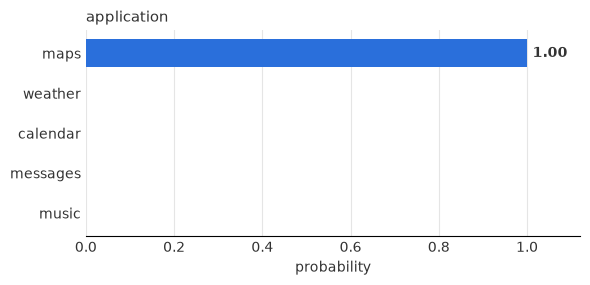

ChoiceAnswer(type='choice', choice='maps', confidence=1.0, probabilities={'maps': 1.0, 'music': 0.0, 'messages': 0.0, 'calendar': 0.0, 'weather': 0.0})

In [94]:
app_answer = cast(ChoiceAnswer, app_response.answers["application"])
app_name = app_answer.choice
app = VALID_APPLICATIONS[app_name]
plot_probabilities(app_response.answers)
app_answer

## Call 2: which action, within the chosen application?

In [95]:
action_questions = {
    "action": Choice(
        instructions=(
            f"The user is using the {app_name} application "
            f"({app['description']}). Which action do they want?"
        ),
        criteria={
            action_name: action_name.replace("_", " ") for action_name in app["actions"]
        },
    ),
}
action_questions

{'action': Choice(type='choice', instructions='The user is using the maps application (Navigation and location search). Which action do they want?', criteria={'navigate': 'navigate', 'search_nearby': 'search nearby', 'show_traffic': 'show traffic'})}

In [96]:
start = time.perf_counter()
action_response = client.system_one(state=transcript, questions=action_questions)
print(f"Action call took {time.perf_counter() - start:.2f}s")
action_response

Action call took 0.23s


SystemOneResponse(model='jev-1.14.0', usage=Usage(input_tokens=346, output_tokens=44), answers={'action': ChoiceAnswer(type='choice', choice='navigate', confidence=1.0, probabilities={'navigate': 1.0, 'search_nearby': 0.0, 'show_traffic': 0.0})})

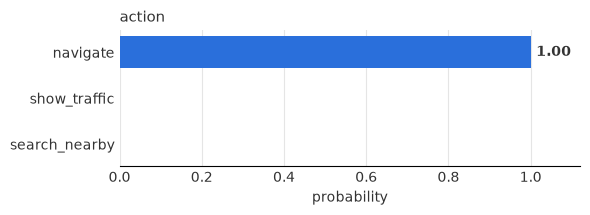

ChoiceAnswer(type='choice', choice='navigate', confidence=1.0, probabilities={'navigate': 1.0, 'search_nearby': 0.0, 'show_traffic': 0.0})

In [97]:
action_answer = cast(ChoiceAnswer, action_response.answers["action"])
action_name = action_answer.choice
plot_probabilities(action_response.answers)
action_answer

## Call 3: extract each parameter as a phrase (start word ID, end word ID)
All the start/end questions go in one call and are answered in parallel.

In [98]:
words = transcript.split()
numbered = "\n".join(f"{i}: {word}" for i, word in enumerate(words))
state = f"transcript: {transcript}\n\nwords (id: word):\n{numbered}"
print(state)

transcript: Hey Google, navigate to Ara.

words (id: word):
0: Hey
1: Google,
2: navigate
3: to
4: Ara.


In [99]:
# Every word ID is a valid choice, plus "none" for parameters not mentioned
word_criteria: dict[str, str | None] = {str(i): word for i, word in enumerate(words)}
word_criteria[NONE_OPTION] = "The parameter is not mentioned in the transcript"

parameters = app["actions"][action_name]
param_questions = {}
for param, param_type in parameters.items():
    described = f'the "{param}" parameter ({param_type}) of the {app_name} {action_name} action'
    param_questions[f"{param}.phrase_start"] = Choice(
        instructions=(
            f"Extract {described} as a phrase from the transcript. "
            "Pick the ID of the FIRST word of the phrase, "
            f'or "{NONE_OPTION}" if it is not mentioned.'
        ),
        criteria=word_criteria,
    )
    param_questions[f"{param}.phrase_end"] = Choice(
        instructions=(
            f"Extract {described} as a phrase from the transcript. "
            "Pick the ID of the LAST word of the phrase, "
            f'or "{NONE_OPTION}" if it is not mentioned.'
        ),
        criteria=word_criteria,
    )
param_questions

{'destination.phrase_start': Choice(type='choice', instructions='Extract the "destination" parameter (str) of the maps navigate action as a phrase from the transcript. Pick the ID of the FIRST word of the phrase, or "none" if it is not mentioned.', criteria={'0': 'Hey', '1': 'Google,', '2': 'navigate', '3': 'to', '4': 'Ara.', 'none': 'The parameter is not mentioned in the transcript'}),
 'destination.phrase_end': Choice(type='choice', instructions='Extract the "destination" parameter (str) of the maps navigate action as a phrase from the transcript. Pick the ID of the LAST word of the phrase, or "none" if it is not mentioned.', criteria={'0': 'Hey', '1': 'Google,', '2': 'navigate', '3': 'to', '4': 'Ara.', 'none': 'The parameter is not mentioned in the transcript'}),
 'mode.phrase_start': Choice(type='choice', instructions='Extract the "mode" parameter (driving | walking | cycling | transit) of the maps navigate action as a phrase from the transcript. Pick the ID of the FIRST word of th

Parameter call took 0.24s


SystemOneResponse(model='jev-1.14.0', usage=Usage(input_tokens=871, output_tokens=239), answers={'destination.phrase_start': ChoiceAnswer(type='choice', choice='4', confidence=1.0, probabilities={'0': 0.0, '1': 0.0, '2': 0.0, '3': 0.0, '4': 1.0, 'none': 0.0}), 'destination.phrase_end': ChoiceAnswer(type='choice', choice='4', confidence=1.0, probabilities={'0': 0.0, '1': 0.0, '2': 0.0, '3': 0.0, '4': 1.0, 'none': 0.0}), 'mode.phrase_start': ChoiceAnswer(type='choice', choice='none', confidence=1.0, probabilities={'0': 0.0, '1': 0.0, '2': 0.0, '3': 0.0, '4': 0.0, 'none': 1.0}), 'mode.phrase_end': ChoiceAnswer(type='choice', choice='none', confidence=1.0, probabilities={'0': 0.0, '1': 0.0, '2': 0.0, '3': 0.0, '4': 0.0, 'none': 1.0})})

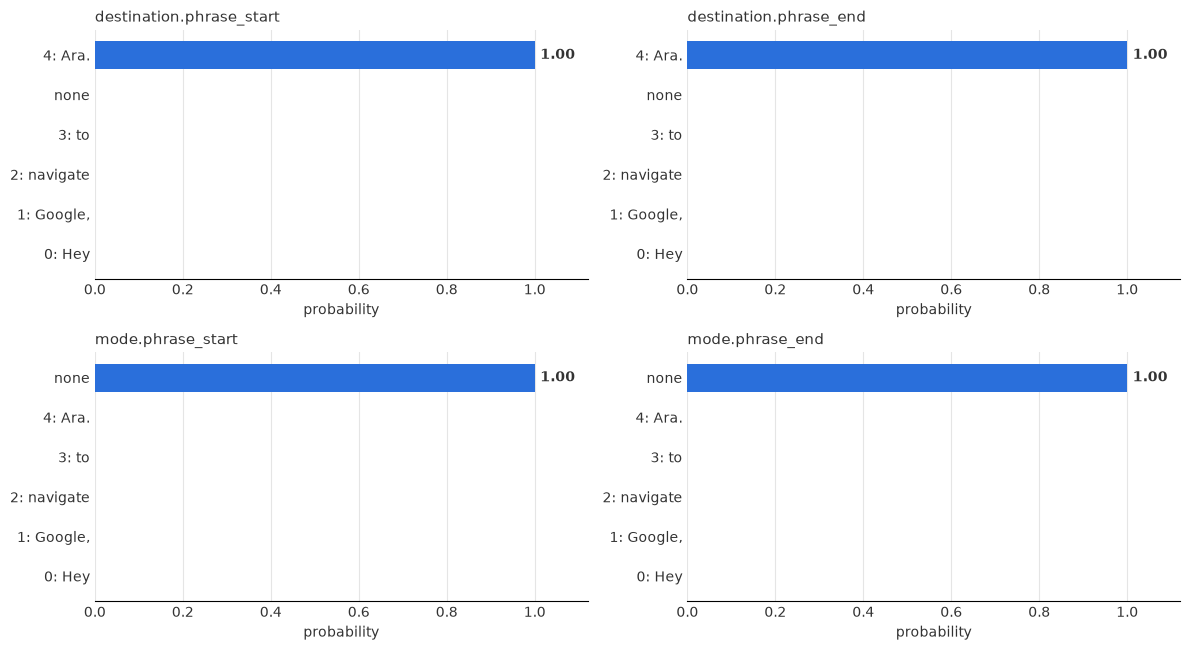

  destination: start=4 end=4
  mode: start=none end=none


In [100]:
extracted: dict[str, str | None] = {}
if param_questions:
    start = time.perf_counter()
    param_response = client.system_one(state=state, questions=param_questions)
    print(f"Parameter call took {time.perf_counter() - start:.2f}s")
    display(param_response)
    # Label word-ID options with their word, e.g. "4: Ara."
    word_labels = {str(i): f"{i}: {word}" for i, word in enumerate(words)}
    plot_probabilities(param_response.answers, display_names=word_labels)

    for param in parameters:
        start_id = param_response.answers[f"{param}.phrase_start"].choice
        end_id = param_response.answers[f"{param}.phrase_end"].choice
        print(f"  {param}: start={start_id} end={end_id}")
        if NONE_OPTION in (start_id, end_id):
            extracted[param] = None
            continue
        first, last = sorted((int(start_id), int(end_id)))
        extracted[param] = " ".join(words[first : last + 1]).strip(".,!?")

In [101]:
client.__exit__(None, None, None)

## Result

In [102]:
result = {
    "target_application": app_name,
    "target_action": action_name,
    "additional_parameters": {k: v for k, v in extracted.items() if v is not None},
}
JSON(result)

<IPython.core.display.JSON object>